# Inherent Structures: Langevin to Quench
This notebook runs the temperature experiment directly from Colab: equilibrate with full-batch Langevin dynamics, quench with full-batch gradient descent, and measure the loss and overlap at the inherent structure.

In [ ]:
# Colab setup: mount Google Drive and keep the repository/results persistent.
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive")
REPO_ROOT = DRIVE_ROOT / "Comparing_Dynamics"
EXPERIMENT_ROOT = DRIVE_ROOT / "STUDIA/PhD/ICML_2026_Hessian_Eigenvectors"
REPO_URL = "https://github.com/marjankowskam/Comparing_Dynamics.git"

%cd {REPO_ROOT}
%pip install -r requirements.txt
%pip install -e .

NameError: name 'drive' is not defined

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(REPO_ROOT))

import torch
import wandb

from comparing_dynamics.config import Config
from comparing_dynamics.models import get_model
from comparing_dynamics.train_utils import init_weights, set_random_seed
from comparing_dynamics.experiments.inherent_structures import (
    InherentStructureConfig,
    run_inherent_structure,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
output_dir = EXPERIMENT_ROOT / "inherent-structures"

In [ ]:
cfg = Config(
    initial_seed=19,
    task_name="mnist",
    task_params={"batch_size": None, "data_dir": "data"},
    model_name="mnistMLP",
    model_params={
        "hidden_dim": [100, 100, 10],
        "activation_fn": "relu",
    },
)

equilibration_steps = 1000*100
quench_steps = 50000
langevin_lr = 1e-3 
quench_lr = 0.014
temperatures = [0.0, 0.01, 0.1, 1.0]

In [ ]:
results = []

for temperature in temperatures:
    cfg.initial_seed = 19
    wb_run = wandb.init(
        project="comparing-dynamics",
        name=f"mnist-langevin-T-{temperature:g}-{cfg.initial_seed}",
        config={
            "temperature": temperature,
            "equilibration_steps": equilibration_steps,
            "quench_steps": quench_steps,
            "langevin_lr": langevin_lr,
            "quench_lr": quench_lr,
            "wandb_log_every": 100,
            "device": device,
        },
    )
    try:
        experiment_cfg = InherentStructureConfig(
            temperature=temperature,
            equilibration_steps=equilibration_steps,
            quench_steps=quench_steps,
            langevin_lr=langevin_lr,
            quench_lr=quench_lr,
            wandb_log_every=100,
            seed=cfg.initial_seed,
        )
        result = run_inherent_structure(
            cfg,
            experiment_cfg,
            device=device,
            save_dir=output_dir,
            run_name=wb_run.name,
        )
        wandb.log({
            "inherent_loss": result["final_loss"],
            "inherent_gradient_norm": result["final_gradient_norm"],
            "overlap_q": result["overlap_q"],
            "initial_to_inherent_overlap": result["initial_to_inherent_overlap"],
        })
        results.append(result)
    finally:
        wandb.finish()

In [ ]:
import pandas as pd

summary = pd.DataFrame([
    {
        "temperature": result["temperature"],
        "inherent_loss": result["final_loss"],
        "gradient_norm": result["final_gradient_norm"],
        "overlap_q": result["overlap_q"],
        "initial_to_inherent_overlap": result["initial_to_inherent_overlap"],
    }
    for result in results
])
summary

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(summary["temperature"], summary["inherent_loss"], marker="o")
axes[0].set(xlabel="Temperature T", ylabel="Inherent-structure loss")
axes[1].plot(summary["temperature"], summary["overlap_q"], marker="o")
axes[1].set(xlabel="Temperature T", ylabel="q(T)")
fig.tight_layout()

# SGD to Quench


In [1]:
import sys
!{sys.executable} -m pip install -e "C:/Users/mmarc/Documents/code/Comparing_Dynamics"

Obtaining file:///C:/Users/mmarc/Documents/code/Comparing_Dynamics
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for comparing-dynamics (pyproject.toml): started
  Building editable for comparing-dynamics (pyproject.toml): finished with status 'done'
  Created wheel for comparing-dynamics: filename=comparing_dynamics-0.1.0-0.editable-py3-none-any.whl size=2903 sha256=320f86dea4b57f6d82928ff6be1dba7224a982d896f33287b7d37fc24dc45d5f
  Stored in directory: C:\Users\mmarc\AppData\Local\Temp\pip-ephem-wheel-cache-wkh1rczc\wheels\

In [7]:
import sys
from pathlib import Path

REPO_ROOT = Path(r"C:/Users/mmarc/Documents/code/Comparing_Dynamics")
sys.path.insert(0, str(REPO_ROOT))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from comparing_dynamics.config import Config
import gc

In [20]:
df_metrics

""


In [9]:
# Load the W&B export from the repository data directory.
# base_path = EXPERIMENT_ROOT
metrics_path =  "../data/wandb_export_ICML_runs.csv"
df = pd.read_csv(metrics_path)

# Normalize the W&B export so run metadata and metrics use stable column names.
df = df.rename(columns={
    "Name": "run_name",
})
required_columns = {"run_name", "opt_name", "task_name", "loss", "accuracy", "grad_norm"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError(f"Missing columns in W&B export: {sorted(missing_columns)}")

filtered = df[
    df["opt_name"].astype(str).str.lower().eq("sgd")
    & df["task_name"].astype(str).str.lower().isin(["fmnist", "fashion_mnist"])
].drop_duplicates(subset=["run_name"])
metrics_by_run = df.set_index("run_name")
df_metrics = df  # Compatibility with the exploratory cells below.
filtered[["run_name", "opt_name", "task_name"]]

,run_name,opt_name,task_name
23,icy-shape-324,sgd,fashion_mnist
27,noble-glitter-320,sgd,fashion_mnist
28,honest-night-313,sgd,fashion_mnist
29,honest-frost-312,sgd,fashion_mnist
30,ethereal-disco-311,sgd,fashion_mnist
31,pious-haze-310,sgd,fashion_mnist
32,graceful-dragon-309,sgd,fashion_mnist
33,sleek-sea-308,sgd,fashion_mnist
34,hearty-sea-307,sgd,fashion_mnist
35,dandy-donkey-306,sgd,fashion_mnist


In [10]:
run_names =filtered["run_name"].values

In [11]:

"there are " + str(len(filtered)) + " available runs"

'there are 45 available runs'

In [ ]:
DRIVE_ROOT = Path("G:\My Drive")
EXPERIMENT_ROOT = DRIVE_ROOT / "STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/"

<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:1: SyntaxWarning: invalid escape sequence '\M'
C:\Users\mmarc\AppData\Local\Temp\ipykernel_37696\3105312329.py:1: SyntaxWarning: invalid escape sequence '\M'
  DRIVE_ROOT = Path("G:\My Drive")


In [35]:
import json

T = {}
for run_name in filtered["run_name"]:
    config_paths = [
        EXPERIMENT_ROOT / f"Config_{run_name}",
        EXPERIMENT_ROOT / f"perturbation_analysisConfig_{run_name}",
    ]
    config_path = next(
        (path for path in config_paths if path.exists()),
        None,
    )
    if config_path is None:
        print(f"Missing config for {run_name}; checked: {config_paths}")
        continue

    with config_path.open() as config_file:
        run_cfg = Config(**json.load(config_file))

    batch_size = run_cfg.task_params.get("batch_size")
    if batch_size is None or batch_size == 0:
        raise ValueError(f"Invalid batch size for {run_name}: {batch_size}")
    T[run_name] = run_cfg.opt_params["lr"] / batch_size

T

Missing config for honest-night-313; checked: [WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/Config_honest-night-313'), WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/perturbation_analysisConfig_honest-night-313')]
Missing config for grievous-xwing-130; checked: [WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/Config_grievous-xwing-130'), WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/perturbation_analysisConfig_grievous-xwing-130')]
Missing config for jedi-jawa-129; checked: [WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/Config_jedi-jawa-129'), WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/perturbation_analysisConfig_jedi-jawa-129')]
Missing config for ancient-lightsaber-128; checked: [WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/Config_ancient-lightsaber-128'), WindowsPath('G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors/perturbation_an

{'icy-shape-324': 1.6666666666666668e-07,
 'noble-glitter-320': 7.8125e-05,
 'honest-frost-312': 7.8125e-06,
 'ethereal-disco-311': 2.34375e-05,
 'pious-haze-310': 0.000234375,
 'graceful-dragon-309': 0.00078125,
 'sleek-sea-308': 7.8125e-06,
 'hearty-sea-307': 2.34375e-05,
 'dandy-donkey-306': 0.000234375,
 'sandy-fog-305': 0.00078125,
 'rare-eon-304': 7.8125e-06,
 'trim-water-303': 2.34375e-05,
 'dutiful-glitter-302': 0.000234375,
 'eager-river-301': 0.00078125,
 'legendary-violet-268': 1.6666666666666668e-07,
 'copper-galaxy-267': 9.765625e-06,
 'fiery-serenity-264': 7.8125e-05,
 'brisk-resonance-260': 0.00015625,
 'stoic-wave-258': 0.0003125,
 'copper-microwave-256': 1.6666666666666668e-07,
 'efficient-pine-254': 9.765625e-06,
 'whole-glitter-252': 7.8125e-05,
 'rural-pyramid-250': 0.00015625,
 'sunny-elevator-248': 0.0003125,
 'rosy-rain-246': 1.6666666666666668e-07,
 'twilight-dragon-244': 9.765625e-06,
 'fanciful-glade-240': 7.8125e-05,
 'pious-waterfall-237': 0.00015625,
 'gene

In [28]:
T.values()

dict_values([1.6666666666666668e-07, 7.8125e-05, 7.8125e-06, 2.34375e-05, 0.000234375, 0.00078125, 7.8125e-06, 2.34375e-05, 0.000234375, 0.00078125, 7.8125e-06, 2.34375e-05, 0.000234375, 0.00078125, 1.6666666666666668e-07, 9.765625e-06, 7.8125e-05, 0.00015625, 0.0003125, 1.6666666666666668e-07, 9.765625e-06, 7.8125e-05, 0.00015625, 0.0003125, 1.6666666666666668e-07, 9.765625e-06, 7.8125e-05, 0.00015625, 0.0003125, 7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05, 7.8125e-05])

Access the leading eigenvalue

In [37]:
# Optional: load leading Hessian eigenvalues when those files are available.

leading_eigenvalue = {}
for run_name in filtered["run_name"]:
    result_path = EXPERIMENT_ROOT / f"hResults_{run_name}.pt"
    if not result_path.exists():
        continue
    hessian_result = torch.load(result_path, weights_only=False, map_location="cpu")
    leading_eigenvalue[run_name] = hessian_result["eig"][-1][0]
    del hessian_result
    gc.collect()

if leading_eigenvalue:
    print(
        np.max(list(leading_eigenvalue.values())),
        np.min(list(leading_eigenvalue.values())),
    )
else:
    print("No Hessian files found; using the configured quench learning rate.")

KeyError: 'eig'

Choose learning rate based on the leading eigenvalue

In [46]:
print(np.max(np.array(list(leading_eigenvalue.values()))), np.min(np.array(list(leading_eigenvalue.values()))))


35.42198 0.042966492


In [47]:
# So we decide to use learning rate
0.5/np.max(np.array(list(leading_eigenvalue.values())))
# i.e. 0.014

np.float32(0.014115529)

Access metrics such as loss, grad_norm and accuracy from the steady state in weights and baises:

In [30]:
metric = df_metrics[["run_name", "loss", "grad_norm", "accuracy"]].set_index("run_name").to_dict(orient="index")

Scatterplot the metrics versus temperature.

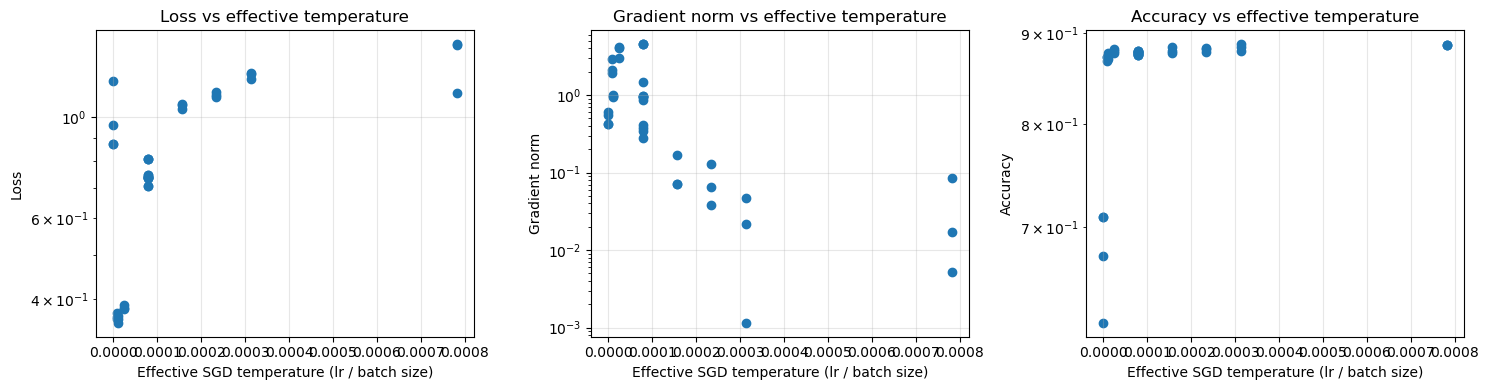

In [36]:
import matplotlib.pyplot as plt
plt.rcParams["text.usetex"] = False

metric = metrics_by_run[["loss", "grad_norm", "accuracy"]].to_dict(orient="index")


def available_metric(run_names, values):
    available = {}
    for run_name in run_names:
        if run_name not in T or run_name not in values:
            continue
        value = values[run_name]
        if pd.notna(value) and np.isfinite(float(value)):
            available[run_name] = float(value)
    return available


metrics = {
    "Loss": available_metric(
        filtered["run_name"],
        {run_name: values["loss"] for run_name, values in metric.items()},
    ),
    "Gradient norm": available_metric(
        filtered["run_name"],
        {run_name: values["grad_norm"] for run_name, values in metric.items()},
    ),
    "Accuracy": available_metric(
        filtered["run_name"],
        {run_name: values["accuracy"] for run_name, values in metric.items()},
    ),
}
if leading_eigenvalue:
    metrics[r"$\lambda_{max}$"] = available_metric(
        filtered["run_name"],
        leading_eigenvalue,
    )

metrics = {
    name: values
    for name, values in metrics.items()
    if values
}
fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4), squeeze=False)
for ax, (metric_name, metric_dict) in zip(axes[0], metrics.items()):
    runs = list(metric_dict)
    ax.scatter([T[run] for run in runs], list(metric_dict.values()))
    ax.set_xlabel("Effective SGD temperature (lr / batch size)")
    ax.set_ylabel(metric_name)
    ax.set_title(f"{metric_name} vs effective temperature")
    ax.grid(alpha=0.3)
    ax.set_yscale("log")

plt.tight_layout()
plt.show()

In [ ]:
quench_steps = 50000
quench_lr = 0.014
quench_tolerance = 1e-6
sgd_to_quench_dir = EXPERIMENT_ROOT / "inherent-structures" / "sgd-to-quench"
sgd_to_quench_dir.mkdir(parents=True, exist_ok=True)
sgd_to_quench_results = []

for run_name in filtered["run_name"]:
    artifact_candidates = [
        (
            EXPERIMENT_ROOT / f"Config_{run_name}",
            EXPERIMENT_ROOT / f"Model_{run_name}.pt",
        ),
        (
            EXPERIMENT_ROOT / f"perturbation_analysisConfig_{run_name}",
            EXPERIMENT_ROOT / f"perturbation_analysisModel_{run_name}.pt",
        ),
    ]
    artifact_paths = next(
        (
            paths
            for paths in artifact_candidates
            if paths[0].exists() and paths[1].exists()
        ),
        None,
    )
    if artifact_paths is None:
        print(f"Missing config/checkpoint for {run_name}; checked: {artifact_candidates}")
        continue

    config_path, checkpoint_path = artifact_paths
    with config_path.open() as config_file:
        run_cfg = Config(**json.load(config_file))
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    set_random_seed(run_cfg.initial_seed)
    model = get_model(run_cfg.model_name, run_cfg.model_params)
    model.apply(init_weights)
    initial_parameters = torch.nn.utils.parameters_to_vector(
        model.parameters()
    ).detach().clone()
    model.load_state_dict(checkpoint["model_state_dict"])

    experiment_cfg = InherentStructureConfig(
        temperature=0.0,
        equilibration_steps=0,
        quench_steps=quench_steps,
        langevin_lr=0.0,
        quench_lr=quench_lr,
        quench_tolerance=quench_tolerance,
        seed=run_cfg.initial_seed,
    )
    result = run_inherent_structure(
        run_cfg,
        experiment_cfg,
        device=device,
        model=model,
        initial_parameters=initial_parameters,
        save_dir=sgd_to_quench_dir,
        run_name=run_name,
    )
    result["run_name"] = run_name
    result["source_config"] = str(config_path)
    result["source_checkpoint"] = str(checkpoint_path)
    sgd_to_quench_results.append(result)

sgd_to_quench_summary = pd.DataFrame([
    {
        "run_name": result["run_name"],
        "effective_temperature": T[result["run_name"]],
        "sgd_loss": metrics_by_run.loc[result["run_name"], "loss"],
        "sgd_accuracy": metrics_by_run.loc[result["run_name"], "accuracy"],
        "sgd_grad_norm": metrics_by_run.loc[result["run_name"], "grad_norm"],
        "inherent_loss": result["final_loss"],
        "inherent_gradient_norm": result["final_gradient_norm"],
        "sgd_to_inherent_overlap": result["overlap_q"],
        "initial_to_inherent_overlap": result["initial_to_inherent_overlap"],
        "source_config": result["source_config"],
        "source_checkpoint": result["source_checkpoint"],
        "checkpoint": result["saved_files"]["inherent_checkpoint"],
    }
    for result in sgd_to_quench_results
])
summary_path = sgd_to_quench_dir / "sgd_to_quench_summary.csv"
sgd_to_quench_summary.to_csv(summary_path, index=False)
print(f"Saved {len(sgd_to_quench_summary)} runs to {sgd_to_quench_dir}")

NameError: name 'EXPERIMENT_ROOT' is not defined